<a href="https://colab.research.google.com/github/Goutham-kc/AIML/blob/main/clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Saving life_expectancy.csv to life_expectancy.csv
Dataset shape: (200, 4)

First 5 rows:
                    Country  Sum of Females  Life Expectancy  \
0                      Chad                            57.19   
1                   Nigeria                            54.94   
2               South Sudan                            60.75   
3                   Lesotho                            60.44   
4  Central African Republic                            59.56   

   Sum of Life Expectancy  (both sexes)  Sum of Males  Life Expectancy  
0                                 55.24                          53.36  
1                                 54.64                          54.33  
2                                 57.74                          54.76  
3                                 57.80                          55.03  
4                                 57.67                          55.51  

Missing values:
Country                                 0
Sum of Females  Life Expectan

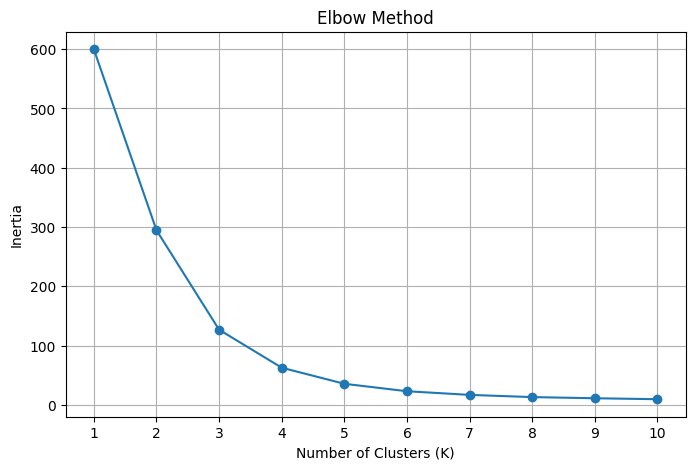


Cluster assignments:
                 Country  Cluster
                  Russia        0
                Paraguay        0
                 Bahamas        0
                  Belize        0
               Lithuania        0
             North Korea        0
                  Bhutan        0
                 Armenia        0
              Azerbaijan        0
                  Latvia        0
               Mauritius        0
                Bulgaria        0
                Thailand        0
                  Mexico        0
               Nicaragua        0
                 Grenada        0
                 Romania        0
                 Curaçao        0
                  Brazil        0
              Cabo Verde        0
           French Guiana        0
                 Mayotte        0
                 Tunisia        0
              Montenegro        0
                    Guam        0
                  Brunei        0
                 Morocco        0
              Bangladesh  

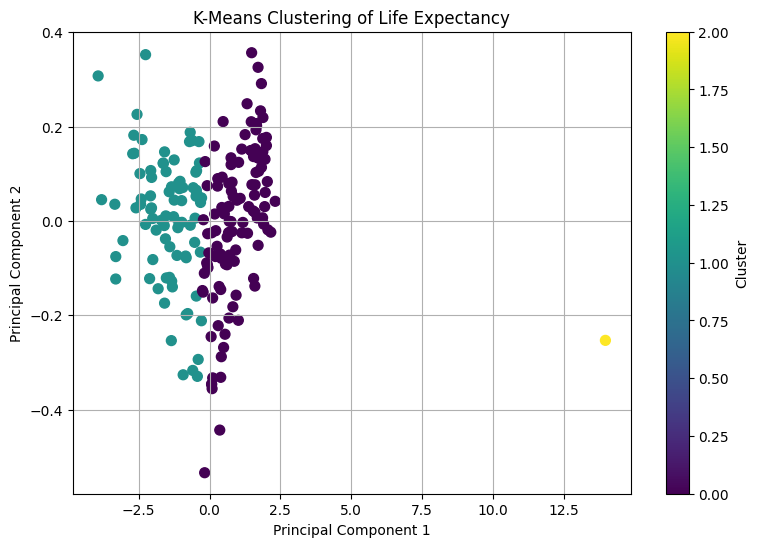

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

# K-Means Clustering on Life Expectancy Dataset

# 1. Import libraries
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

# 2. Upload the dataset
uploaded = files.upload()
filename = next(iter(uploaded))
df = pd.read_csv(filename)

# 3. Display dataset information
print("Dataset shape:", df.shape)
print("\nFirst 5 rows:")
print(df.head())
print("\nMissing values:")
print(df.isnull().sum())

# 4. Select numerical features
features = [
    'Sum of Females  Life Expectancy',
    'Sum of Life Expectancy  (both sexes)',
    'Sum of Males  Life Expectancy'
]

# Clean and prepare the data
X = df[features].apply(pd.to_numeric, errors='coerce')
X = X.fillna(X.median())

# 5. Standardize the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 6. Elbow Method to find the optimal number of clusters
inertia = []
k_values = range(1, 11)

for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X_scaled)
    inertia.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(k_values, inertia, marker='o')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia')
plt.title('Elbow Method')
plt.xticks(list(k_values))
plt.grid(True)
plt.show()

# 7. Apply K-Means with 3 clusters
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df['Cluster'] = kmeans.fit_predict(X_scaled)

# 8. Display results
print("\nCluster assignments:")
print(df[['Country', 'Cluster']].sort_values('Cluster').to_string(index=False))

print("\nNumber of countries in each cluster:")
print(df['Cluster'].value_counts().sort_index())

print("\nAverage life expectancy in each cluster:")
print(df.groupby('Cluster')[features].mean().round(2))

# 9. Visualize clusters using PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(9, 6))
plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=df['Cluster'],
    cmap='viridis',
    s=50
)
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('K-Means Clustering of Life Expectancy')
plt.colorbar(label='Cluster')
plt.grid(True)
plt.show()

# 10. Save the results
df.to_csv('life_expectancy_clusters.csv', index=False)
files.download('life_expectancy_clusters.csv')
